In [1]:
'''В этой работе я хочу научиться использовать логистическую регрессию для прогнозирования оттока клиентов банка.
Я буду использовать датасет из предыдущей работы. В нём содержится информация о клиентах, их счетах, картах, транзакциях и кредитах.
Моя задача — построить модель, которая будет определять, может ли клиент уйти из банка, а затем проверить, насколько хорошо она работает.'''

'В этой работе я хочу научиться использовать логистическую регрессию для прогнозирования оттока клиентов банка.\nЯ буду использовать датасет из предыдущей работы. В нём содержится информация о клиентах, их счетах, картах, транзакциях и кредитах.\nМоя задача — построить модель, которая будет определять, может ли клиент уйти из банка, а затем проверить, насколько хорошо она работает.'

In [2]:
from google.colab import files

uploaded = files.upload()

Saving customer_churn_features.csv to customer_churn_features.csv


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42


In [4]:

df = pd.read_csv("customer_churn_features.csv")

print("Размер датасета:", df.shape)
display(df.head())
print("\nНазвания столбцов:")
print(df.columns.tolist())


Размер датасета: (10000, 22)


,customer_id,age,gender,registration_date,annual_income,account_count,active_account_count,card_count,active_card_count,transaction_count,...,card_purchase_count,atm_withdrawal_count,transfer_out_count,utility_payment_count,transfer_count,loan_count,total_loan_amount,avg_interest_rate,last_transaction_date,churn
0,1,34,M,2025-07-12,455276.04,1,1,1,1,266,...,249,5,0,0,0,0,0.0,0.0,2026-01-27,0
1,2,54,M,2025-03-22,1945830.96,2,2,1,1,465,...,434,9,0,4,0,0,0.0,0.0,2026-01-26,0
2,3,18,F,2025-10-01,315794.16,1,1,1,1,155,...,144,2,1,1,1,0,0.0,0.0,2026-01-27,0
3,4,18,F,2025-11-22,647645.88,2,2,1,1,76,...,70,2,0,2,0,0,0.0,0.0,2026-01-25,0
4,5,49,M,2025-09-30,1061109.84,2,2,0,0,165,...,153,2,0,3,0,0,0.0,0.0,2026-01-27,0



Названия столбцов:
['customer_id', 'age', 'gender', 'registration_date', 'annual_income', 'account_count', 'active_account_count', 'card_count', 'active_card_count', 'transaction_count', 'total_transaction_amount', 'avg_transaction_amount', 'card_purchase_count', 'atm_withdrawal_count', 'transfer_out_count', 'utility_payment_count', 'transfer_count', 'loan_count', 'total_loan_amount', 'avg_interest_rate', 'last_transaction_date', 'churn']


In [5]:
'''Проверяем целевую переменную
Что мы ожидаем увидеть: в предыдущей работе было 10 000 клиентов, из которых около 6,97% имели churn = 1.
Если данные не изменились, распределение будет примерно таким же.'''

'Проверяем целевую переменную\nЧто мы ожидаем увидеть: в предыдущей работе было 10 000 клиентов, из которых около 6,97% имели churn = 1. \nЕсли данные не изменились, распределение будет примерно таким же.'

In [6]:

print("Распределение целевой переменной:")
print(df["churn"].value_counts())

print("\nРаспределение в процентах:")
print((df["churn"].value_counts(normalize=True) * 100).round(2))

print("\nПропущенные значения:")
print(df.isnull().sum().sum())


Распределение целевой переменной:
churn
0    9303
1     697
Name: count, dtype: int64

Распределение в процентах:
churn
0    93.03
1     6.97
Name: proportion, dtype: float64

Пропущенные значения:
0


In [ ]:
'''Будем предсказывать churn по пяти признакам:
Признак	Что означает
age	Возраст клиента
annual_income	Годовой доход
active_account_count	Количество активных счетов
transaction_count	Количество транзакций
loan_count	Количество кредитов

Выбрала эти признаки, потому что они описывают возраст и доход клиента, а также то, насколько активно он пользуется услугами банка.
Далее проверяем выбранные признаки'''

In [7]:

features = [
    "age",
    "annual_income",
    "active_account_count",
    "transaction_count",
    "loan_count"
]

target = "churn"

print("Выбранные признаки:")
display(df[features].describe().round(2))

print("Целевая переменная:")
print(df[target].value_counts())


Выбранные признаки:


,age,annual_income,active_account_count,transaction_count,loan_count
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,48.56,1628445.38,1.54,288.73,0.29
std,18.06,1363651.83,0.58,134.43,0.51
min,17.00,0.00,1.00,27.00,0.00
25%,33.00,589474.53,1.00,175.00,0.00
50%,48.00,1237692.84,1.00,287.00,0.00
75%,64.00,2156063.37,2.00,397.00,1.00
max,80.00,9063431.40,3.00,620.00,2.00


Целевая переменная:
churn
0    9303
1     697
Name: count, dtype: int64


In [ ]:
'''Для обучения модели я разделила данные на две части: 80% для обучения и 20% для проверки результата.
При разделении я сохранила соотношение клиентов с оттоком и без оттока. Это важно, потому что клиентов с оттоком в датасете значительно меньше.'''

In [8]:

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

print("\nОтток в обучающей выборке, %:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nОтток в тестовой выборке, %:")
print((y_test.value_counts(normalize=True) * 100).round(2))


Размер обучающей выборки: (8000, 5)
Размер тестовой выборки: (2000, 5)

Отток в обучающей выборке, %:
churn
0    93.02
1     6.98
Name: proportion, dtype: float64

Отток в тестовой выборке, %:
churn
0    93.05
1     6.95
Name: proportion, dtype: float64


In [ ]:
'''- Для обучения модели  8000 клиентов.
- Для проверки модели — 2000 клиентов.
- Доля клиентов с оттоком в обеих выборках почти одинаковая: около 7%.
Теперь модель сможет учиться на одной части данных, а мы проверим её на другой, которую она не видела при обучении.'''

In [ ]:
'''На следующем этапе я обучу модель логистической регрессии.
Она будет использовать пять признаков клиента, чтобы оценивать вероятность его оттока.
Перед обучением я приведу числовые признаки к похожему масштабу.
Это поможет модели корректно работать с показателями, значения которых сильно отличаются, например с возрастом и годовым доходом.'''

In [9]:

model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Модель обучена!")
print("Количество объектов для обучения:", len(X_train))
print("Количество признаков:", X_train.shape[1])


Модель обучена!
Количество объектов для обучения: 8000
Количество признаков: 5


In [10]:
# Получаем вероятность оттока для каждого клиента
y_proba = model.predict_proba(X_test)[:, 1]

# Выводим вероятности для первых 10 клиентов
print("Вероятность оттока для первых 10 клиентов:")
print(np.round(y_proba[:10], 3))

Вероятность оттока для первых 10 клиентов:
[0.485 0.5   0.5   0.504 0.513 0.492 0.48  0.52  0.504 0.498]


In [ ]:
'''Модель рассчитала вероятность оттока для первых 10 клиентов. Например, для первого клиента вероятность составляет 48,5%, а для пятого — 51,3%.
Вероятности пока близки к 50%. Это нормально для первого просмотра, но нам нужно проверить качество модели с помощью графиков.
Построю ROC-кривой и Precision-Recall кривой
Эти графики помогут понять, насколько хорошо модель отличает клиентов, которые уйдут из банка, от тех, кто останется.'''

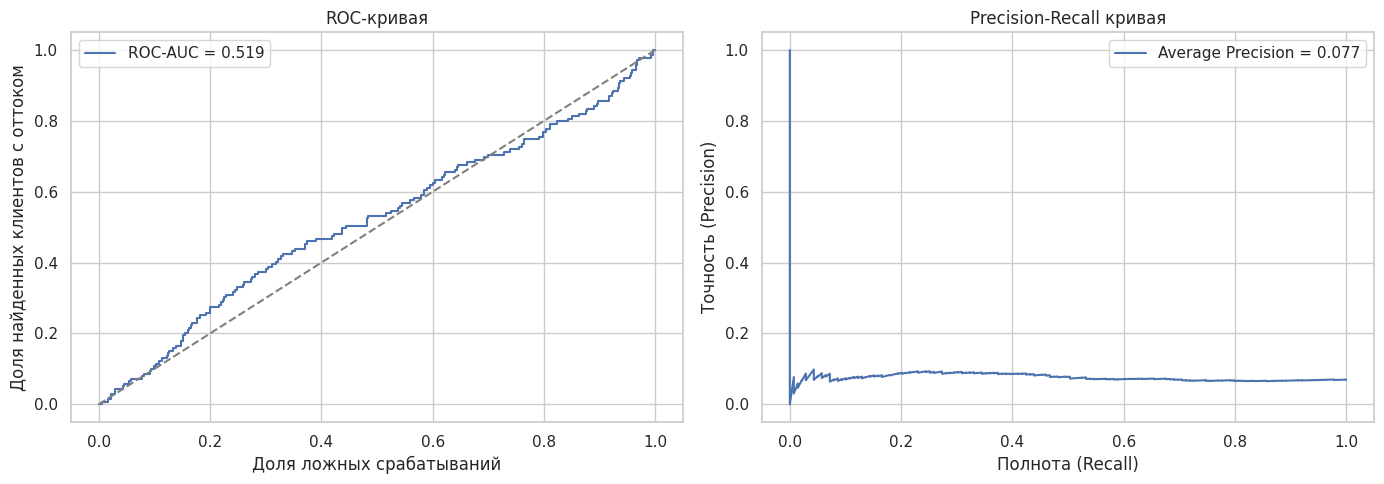

ROC-AUC: 0.519
Average Precision: 0.077


In [11]:
# Рассчитываем данные для ROC-кривой
fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

# Рассчитываем данные для Precision-Recall кривой
precision, recall, pr_thresholds = precision_recall_curve(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

# Строим два графика
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC-кривая
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_title("ROC-кривая")
axes[0].set_xlabel("Доля ложных срабатываний")
axes[0].set_ylabel("Доля найденных клиентов с оттоком")
axes[0].legend()

# Precision-Recall кривая
axes[1].plot(recall, precision, label=f"Average Precision = {pr_auc:.3f}")
axes[1].set_title("Precision-Recall кривая")
axes[1].set_xlabel("Полнота (Recall)")
axes[1].set_ylabel("Точность (Precision)")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc:.3f}")
print(f"Average Precision: {pr_auc:.3f}")

In [ ]:
'''пока модель плохо определяет, какие клиенты могут уйти из банка. Это нормально для эксперимента
— теперь попробуем разобраться, почему так происходит.'''

Accuracy: 0.578
Precision: 0.078
Recall: 0.468
F1-score: 0.133

Отчёт о качестве модели:
              precision    recall  f1-score   support

           0       0.94      0.59      0.72      1861
           1       0.08      0.47      0.13       139

    accuracy                           0.58      2000
   macro avg       0.51      0.53      0.43      2000
weighted avg       0.88      0.58      0.68      2000



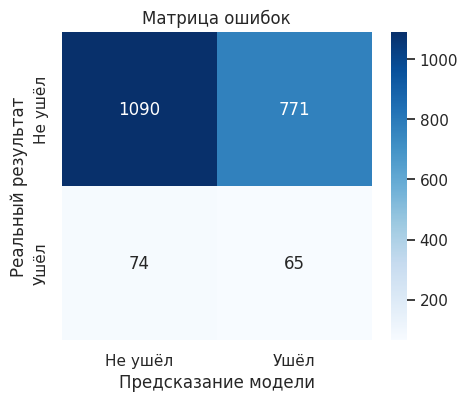

In [12]:
# Получаем предсказанные классы
y_pred = model.predict(X_test)

# Выводим основные метрики
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 3))

# Отчёт по каждому классу
print("\nОтчёт о качестве модели:")
print(classification_report(y_test, y_pred, zero_division=0))

# Матрица ошибок
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Не ушёл", "Ушёл"],
    yticklabels=["Не ушёл", "Ушёл"]
)
plt.xlabel("Предсказание модели")
plt.ylabel("Реальный результат")
plt.title("Матрица ошибок")
plt.show()

In [ ]:
'''Recall = 0.468: модель находит почти половину клиентов, которые действительно ушли из банка.
Precision = 0.078: при этом большинство клиентов, которых модель относит к уходящим, на самом деле не уходят
Accuracy = 0.578: эту метрику нужно оценивать осторожно, потому что классы в датасете сильно различаются по численности.
ROC-AUC = 0.519: модель пока почти не умеет различать клиентов двух классов.'''

In [ ]:
'''В этой работе я построила модель логистической регрессии для прогнозирования оттока клиентов банка.
Для обучения использовала 5 признаков: возраст, годовой доход, количество активных счетов, количество транзакций и количество кредитов.

Данные были разделены на обучающую и тестовую выборки в соотношении 80/20.
Для подготовки данных использовалась стандартизация признаков, а для работы с несбалансированными классами — параметр class_weight="balanced".

ROC-AUC составил 0,519, а F1-score — 0,133. Модель смогла найти 46,8% клиентов с оттоком,
но точность таких предсказаний оказалась низкой.
Таким образом, полученная модель пока недостаточно хорошо прогнозирует отток клиентов.
В дальнейшем можно попробовать использовать другие признаки и сравнить результаты с другими моделями машинного обучения.'''

In [ ]:
'''сейчас модель использует стандартный порог 0.5. Поскольку у нас есть вероятности оттока,
можно выбрать другой порог, ориентируясь на Precision-Recall кривую.'''

In [13]:
# Делим обучающие данные на внутренние обучающую и проверочную части
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Обучаем временную модель
validation_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

validation_model.fit(X_subtrain, y_subtrain)

# Вероятности оттока на проверочной части
y_val_proba = validation_model.predict_proba(X_val)[:, 1]

# Строим Precision-Recall данные
val_precision, val_recall, val_thresholds = precision_recall_curve(
    y_val, y_val_proba
)

# Рассчитываем F1 для разных порогов
f1_values = (
    2 * val_precision[:-1] * val_recall[:-1]
    / (val_precision[:-1] + val_recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_values)
best_threshold = val_thresholds[best_index]

print("Выбранный порог:", round(best_threshold, 3))
print("Precision на проверочной выборке:",
      round(val_precision[best_index], 3))
print("Recall на проверочной выборке:",
      round(val_recall[best_index], 3))
print("F1-score на проверочной выборке:",
      round(f1_values[best_index], 3))

Выбранный порог: 0.495
Precision на проверочной выборке: 0.077
Recall на проверочной выборке: 0.777
F1-score на проверочной выборке: 0.14


In [14]:
# Получаем вероятности оттока на тестовой выборке
y_proba = model.predict_proba(X_test)[:, 1]

# Применяем выбранный порог
threshold = best_threshold
y_pred_threshold = (y_proba >= threshold).astype(int)

# Рассчитываем метрики
print("Выбранный порог:", round(threshold, 3))
print("Accuracy:", round(accuracy_score(y_test, y_pred_threshold), 3))
print("Precision:", round(precision_score(y_test, y_pred_threshold, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred_threshold, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred_threshold, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))
print("Average Precision:", round(average_precision_score(y_test, y_proba), 3))

Выбранный порог: 0.495
Accuracy: 0.423
Precision: 0.071
Recall: 0.604
F1-score: 0.127
ROC-AUC: 0.519
Average Precision: 0.077


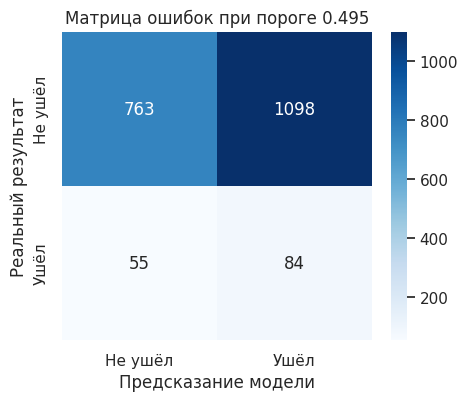

              precision    recall  f1-score   support

     Не ушёл       0.93      0.41      0.57      1861
        Ушёл       0.07      0.60      0.13       139

    accuracy                           0.42      2000
   macro avg       0.50      0.51      0.35      2000
weighted avg       0.87      0.42      0.54      2000



In [15]:
cm = confusion_matrix(y_test, y_pred_threshold)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Не ушёл", "Ушёл"],
    yticklabels=["Не ушёл", "Ушёл"]
)
plt.xlabel("Предсказание модели")
plt.ylabel("Реальный результат")
plt.title(f"Матрица ошибок при пороге {threshold:.3f}")
plt.show()

print(classification_report(
    y_test,
    y_pred_threshold,
    target_names=["Не ушёл", "Ушёл"],
    zero_division=0
))

In [ ]:
'''При снижении порога модель стала находить больше клиентов с оттоком:
Recall вырос с 46,8% до 60,4%. Но при этом увеличилось количество ложных срабатываний, поэтому Accuracy и Precision снизились.

Интересно, что на проверочной выборке порог 0.495 давал Recall 77,7%,
а на тестовой — 60,4%. Это нормально: результаты на разных выборках могут отличаться.
На тестовой выборке мы оцениваем, как модель работает на новых данных.

порог 0.495 не улучшил F1-score на тестовой выборке относительно порога 0.5.
 Но он может быть полезен, если для банка важнее обнаруживать больше потенциально
 уходящих клиентов, даже ценой дополнительных ложных срабатываний.'''

In [16]:
# Получаем коэффициенты обученной модели
coefficients = model.named_steps["logistic_regression"].coef_[0]

coef_df = pd.DataFrame({
    "Признак": features,
    "Коэффициент": coefficients
})

coef_df["Направление связи"] = np.where(
    coef_df["Коэффициент"] > 0,
    "Связь с увеличением вероятности оттока",
    "Связь с уменьшением вероятности оттока"
)

coef_df["Коэффициент"] = coef_df["Коэффициент"].round(3)

display(coef_df.sort_values("Коэффициент", ascending=False))

,Признак,Коэффициент,Направление связи
4,loan_count,0.035,Связь с увеличением вероятности оттока
1,annual_income,0.012,Связь с увеличением вероятности оттока
2,active_account_count,0.011,Связь с увеличением вероятности оттока
0,age,-0.013,Связь с уменьшением вероятности оттока
3,transaction_count,-0.022,Связь с уменьшением вероятности оттока


In [ ]:
'''

я построила модель логистической регрессии для прогнозирования оттока клиентов банка.
В качестве целевой переменной использовалась `churn`: 0 — клиент не ушёл, 1 — клиент ушёл.

Для обучения модели я выбрала пять признаков: возраст, годовой доход,
количество активных счетов, количество транзакций и количество кредитов.
Данные были разделены на обучающую и тестовую выборки в соотношении 80/20.
Перед обучением признаки были стандартизированы. Также использовался параметр
`class_weight="balanced"`, потому что клиентов с оттоком в датасете значительно меньше.

Для оценки качества модели были построены ROC- и Precision-Recall-кривые.
Значение ROC-AUC составило 0,519, а Average Precision — 0,077. Это показывает, что модель плохо различает клиентов с оттоком и без него.

На проверочной выборке я выбрала порог предсказания 0,495 по максимальному значению
F1-score. На тестовой выборке при этом пороге Accuracy составил 0,423, Precision — 0,071,
 Recall — 0,604, а F1-score — 0,127. Модель обнаруживает 60,4% клиентов с оттоком, но
 среди клиентов, которых она относит к уходящим, много ложных срабатываний.

Анализ коэффициентов показал, что в построенной модели `loan_count`, `annual_income` и
`active_account_count` имеют положительные коэффициенты. Это означает, что при увеличении
этих признаков прогнозируемая вероятность оттока имеет тенденцию увеличиваться при прочих
равных условиях. Признаки `age` и `transaction_count` имеют отрицательные коэффициенты, то
есть связаны со снижением прогнозируемой вероятности оттока при прочих равных условиях.

При этом коэффициенты небольшие, а качество модели низкое, поэтому эти зависимости нужно
интерпретировать осторожно. Они не доказывают, что именно эти признаки вызывают отток клиентов.

В результате я научилась обучать логистическую регрессию, строить графики оценки качества,
выбирать порог классификации, строить матрицу ошибок и рассчитывать метрики. Для улучшения
модели можно попробовать другие признаки и сравнить результаты с другими алгоритмами машинного обучения.'''